# Install packages:

In [1]:
%pip install qiskit qiskit_aer qiskit[visualization]

# Import Packages and build quantum circuit

In [2]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, array_to_latex

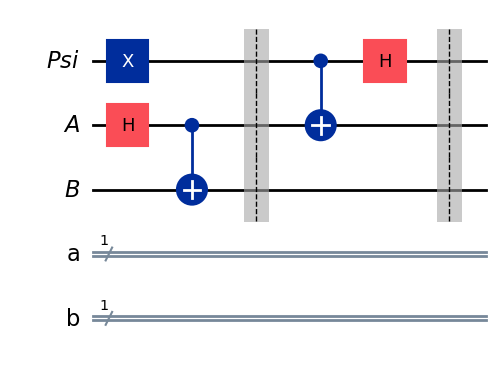

In [3]:
# Define Quantum and Classical Registers
qubit = QuantumRegister(1, "Psi")
ebit0 = QuantumRegister(1, "A")
ebit1 = QuantumRegister(1, "B")
a = ClassicalRegister(1, "a")
b = ClassicalRegister(1, "b")

protocol = QuantumCircuit(qubit, ebit0, ebit1, a, b)

# Prepare state psi that Alice wants to transport:
protocol.x(qubit)

# Prepare ebit used for teleportation
protocol.h(ebit0)
protocol.cx(ebit0, ebit1)
protocol.barrier()

# Alice's operations
protocol.cx(qubit, ebit0)
protocol.h(qubit)
protocol.barrier()
display(protocol.draw(output="mpl"))

$$
\vert \pi_0 \rangle
= \vert \phi^+\rangle \otimes
\bigl(\alpha\vert 0\rangle + \beta\vert 1\rangle \bigr)
= \frac{\alpha \vert 000 \rangle + \alpha \vert 110\rangle + \beta \vert 001\rangle + \beta \vert 111\rangle}{\sqrt{2}}.
$$

The first gate that is performed is the controlled-NOT gate, which transforms the state $\vert\pi_0\rangle$ into

$$
\vert \pi_1 \rangle  = \frac{\alpha \vert 000 \rangle + \alpha \vert 110\rangle + \beta \vert 011\rangle + \beta \vert 101\rangle}{\sqrt{2}}.
$$

Then the Hadamard gate is applied, which transforms the state $\vert\pi_1\rangle$ into

$$
\begin{aligned}
\vert\pi_2\rangle
& =
\frac{\alpha \vert 00\rangle \vert + \rangle + \alpha \vert 11\rangle\vert +\rangle + \beta \vert 01\rangle\vert -\rangle + \beta \vert 10\rangle\vert -\rangle}{\sqrt{2}}\\[2mm]
& = \frac{\alpha \vert 000 \rangle
+ \alpha \vert 001 \rangle
+ \alpha \vert 110 \rangle
+ \alpha \vert 111 \rangle
+ \beta \vert 010 \rangle
- \beta \vert 011 \rangle
+ \beta \vert 100 \rangle
- \beta \vert 101 \rangle}{2}.
\end{aligned}
$$

Using the multilinearity of the tensor product, we may alternatively write this state as follows:

$$
\begin{aligned}
\vert\pi_2\rangle = \quad
& \frac{1}{2} \bigl(\alpha\vert 0 \rangle + \beta \vert 1\rangle \bigr)\vert 00\rangle \\[2mm]
+ & \frac{1}{2} \bigl(\alpha\vert 0 \rangle - \beta \vert 1\rangle \bigr)\vert 01\rangle \\[2mm]
+ & \frac{1}{2} \bigl(\alpha\vert 1 \rangle + \beta \vert 0\rangle \bigr)\vert 10\rangle \\[2mm]
+ & \frac{1}{2} \bigl(\alpha\vert 1 \rangle - \beta \vert 0\rangle \bigr)\vert 11\rangle.
\end{aligned}
$$


In [4]:
from qiskit.quantum_info import Statevector

f_state = Statevector(protocol)
f_state.draw("latex")

<IPython.core.display.Latex object>

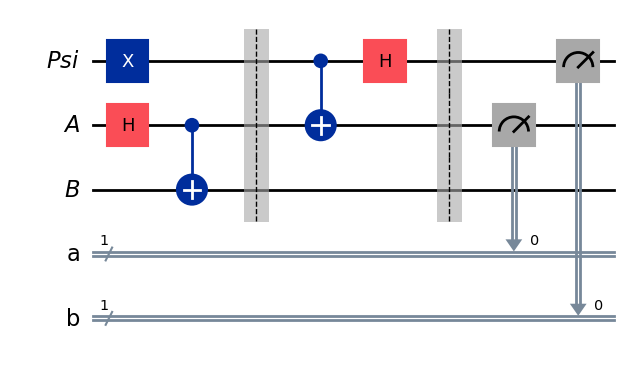

In [5]:
# Alice measures and sends classical bits to Bob
protocol.measure(ebit0, a)
protocol.measure(qubit, b)
display(protocol.draw(output="mpl"))

{'1 1': 2465, '0 1': 2454, '0 0': 2521, '1 0': 2560}


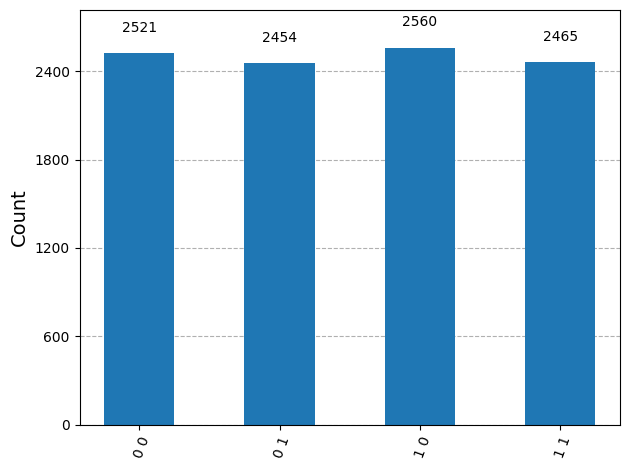

In [8]:
from qiskit_aer import Aer

result = AerSimulator().run(protocol, shots = 10000).result()
statistics = result.get_counts()
print(statistics)
display(plot_histogram(statistics))

{'1 1': 1}


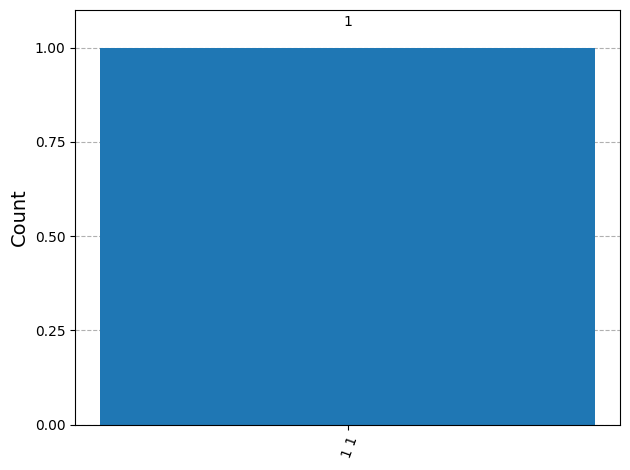

In [11]:
from qiskit_aer import Aer

result = AerSimulator().run(protocol, shots = 1).result()
statistics = result.get_counts()
print(statistics)
display(plot_histogram(statistics))

# Possible outcomes

* The outcome of Alice's measurement is $aq = 00$ with probability

  $$
  \Biggl\| \frac{1}{2}\bigl(\alpha \vert 0\rangle + \beta\vert 1\rangle\bigr) \Biggr\|^2
  = \frac{\vert\alpha\vert^2 + \vert\beta\vert^2}{4} = \frac{1}{4},
  $$

  in which case the state of $(\mathsf{B},\mathsf{A},\mathsf{Q})$ becomes

  $$
  \bigl( \alpha \vert 0 \rangle + \beta \vert 1 \rangle \bigr) \vert 00 \rangle.
  $$

  Bob does nothing in this case, and so this is the final state of these three qubits.

* The outcome of Alice's measurement is $aq = 01$ with probability

  $$
  \Biggl\| \frac{1}{2}\bigl(\alpha \vert 0\rangle - \beta\vert 1\rangle\bigr) \Biggr\|^2
  = \frac{\vert\alpha\vert^2 + \vert{-\beta}\vert^2}{4} = \frac{1}{4},
  $$

  in which case the state of $(\mathsf{B},\mathsf{A},\mathsf{Q})$ becomes

  $$
  \bigl( \alpha \vert 0 \rangle - \beta \vert 1 \rangle \bigr) \vert 01 \rangle.
  $$

  In this case Bob applies a $Z$ gate to $\mathsf{B}$, leaving $(\mathsf{B},\mathsf{A},\mathsf{Q})$ in the state

  $$
  \bigl( \alpha \vert 0 \rangle + \beta \vert 1 \rangle \bigr) \vert 01 \rangle.
  $$

* The outcome of Alice's measurement is $aq = 10$ with probability

  $$
  \Biggl\| \frac{1}{2}\bigl(\alpha \vert 1\rangle + \beta\vert 0\rangle\bigr) \Biggr\|^2
  = \frac{\vert\alpha\vert^2 + \vert\beta\vert^2}{4} = \frac{1}{4},
  $$

  in which case the state of $(\mathsf{B},\mathsf{A},\mathsf{Q})$ becomes

  $$
  \bigl( \alpha \vert 1 \rangle + \beta \vert 0 \rangle \bigr) \vert 10 \rangle.
  $$

  In this case, Bob applies an $X$ gate to the qubit $\mathsf{B}$, leaving $(\mathsf{B},\mathsf{A},\mathsf{Q})$ in the state

  $$
  \bigl( \alpha \vert 0 \rangle + \beta \vert 1 \rangle \bigr) \vert 10 \rangle.
  $$

* The outcome of Alice's measurement is $aq = 11$ with probability

  $$
  \Biggl\| \frac{1}{2}\bigl(\alpha \vert 1\rangle - \beta\vert 0\rangle\bigr) \Biggr\|^2
  = \frac{\vert\alpha\vert^2 + \vert{-\beta}\vert^2}{4} = \frac{1}{4},
  $$

  in which case the state of $(\mathsf{B},\mathsf{A},\mathsf{Q})$ becomes

  $$
  \bigl( \alpha \vert 1 \rangle - \beta \vert 0 \rangle \bigr) \vert 11 \rangle.
  $$

  In this case, Bob performs the operation $ZX$ on the qubit $\mathsf{B}$, leaving $(\mathsf{B},\mathsf{A},\mathsf{Q})$ in the state

  $$
  \bigl( \alpha \vert 0 \rangle + \beta \vert 1 \rangle \bigr) \vert 11 \rangle.
  $$

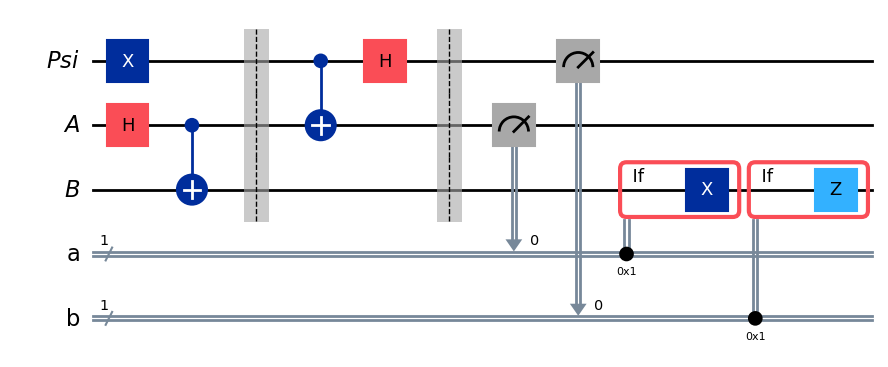

In [12]:
# Bob uses the classical bits to conditionally apply gates
with protocol.if_test((a, 1)):
    protocol.x(ebit1)
with protocol.if_test((b, 1)):
    protocol.z(ebit1)

display(protocol.draw(output="mpl"))

In [13]:
res = ClassicalRegister(1,"result")
protocol.add_register(res)
#protocol.x(ebit1)
protocol.measure(ebit1, res)

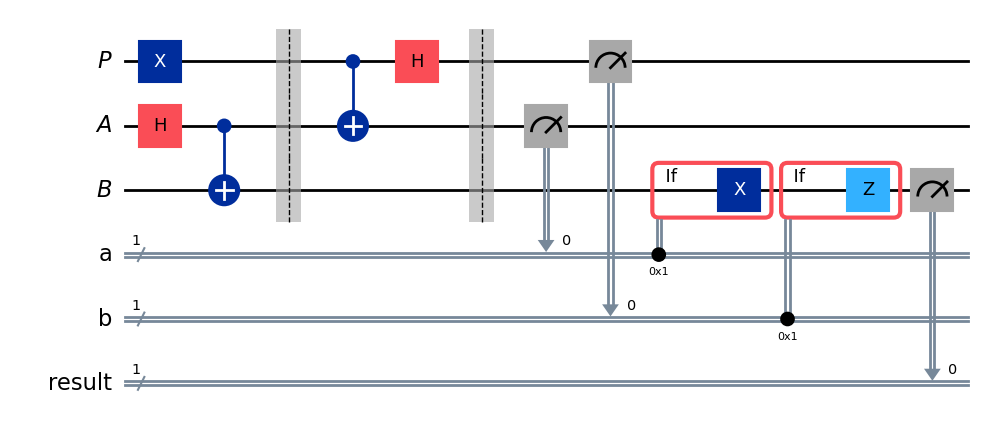

In [ ]:
display(protocol.draw(output="mpl"))

{'1 0 0': 2490, '1 1 0': 2581, '1 0 1': 2477, '1 1 1': 2452}


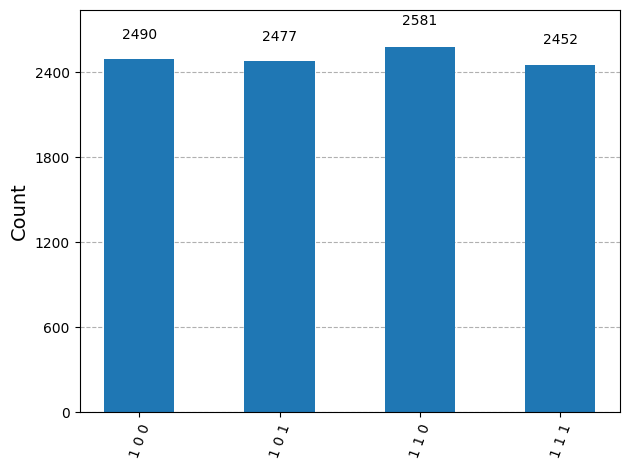

In [14]:
result = AerSimulator().run(protocol, shots = 10000).result()
statistics = result.get_counts()
print(statistics)
display(plot_histogram(statistics))

We can then filter the statistics to focus only on the test result "qubit". This is effectively saying that:
$$P_B = \langle{f}|(|c_i\rangle \langle c_i| \otimes I_A \otimes I_P) |f\rangle$$


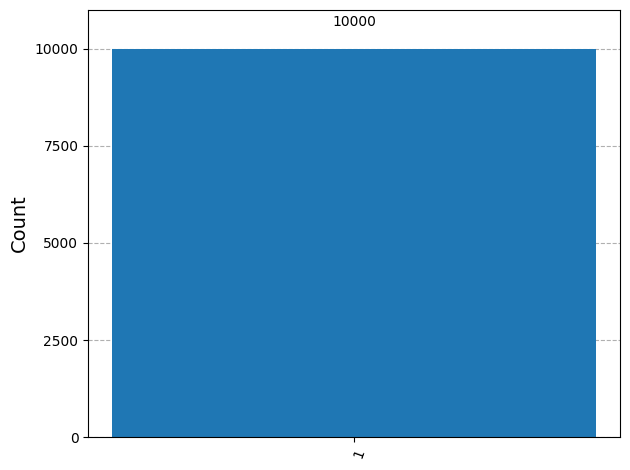

In [ ]:
from qiskit.result import marginal_distribution

filtered_statistics = marginal_distribution(statistics, [2])
display(plot_histogram(filtered_statistics))